# Blockpose detector — frozen Python development diagnostic

This notebook is the rerunnable showcase for the three historical Python
detector modes. It runs the
reviewed real snapshots from a clean kernel and retains its outputs.  The
results are **development diagnostics**, not a production acceptance claim:
all snapshots and plan fixtures are development material.

The colours in real overlays are: grey LiDAR returns, dashed orange
evaluation-only annotation, blue plan prior, and green query result.  Labels
and annotation ROI are opened only **after** each query finishes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def find_repo_root():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / ".."]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "pyproject.toml").is_file() and (candidate / "python/blockpose").is_dir():
            return candidate
    raise RuntimeError("Could not locate repository root from notebook working directory")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blockpose.mode_benchmark import run_mode_benchmark

# These are the CLI defaults.  Changing either value makes the notebook a new
# diagnostic run rather than the frozen default comparison.
REPORT = run_mode_benchmark(timeout_ms=500.0, min_score=0.4)
DISCOVERY = REPORT["modes"]["SCENE_DISCOVERY"]
REFINE = REPORT["modes"]["REFINE_BLOCK"]
GRIPPED = REPORT["modes"]["REFINE_GRASPED"]
print({
    "git_revision": REPORT["git_revision"],
    "created_utc": REPORT["created_utc"],
    "source_worktree_dirty": REPORT["source_worktree_dirty"],
    "source_worktree_status": REPORT["source_worktree_status"],
    "taxonomy_audit": REPORT["taxonomy_audit"],
})

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


{'git_revision': 'c9f069d15e8b2f6ebca0434b426d6503090d2025', 'created_utc': '2026-07-22T16:34:14.333637+00:00', 'source_worktree_dirty': True, 'source_worktree_status': [' M docs/.obsidian/workspace.json', ' M notebooks/blockpose_detector_showcase.ipynb', ' M python/blockpose/verify_placed.py', ' M tests/python/test_detector_showcase.py', ' M tests/python/test_verify_placed.py', ' M tools/build_detector_showcase.py', '?? config/verify_placed_v1_baseline_c9f069d.yaml', '?? docs/next-steps.md', '?? docs/python-mode-benchmark.md', '?? python/blockpose/mode_benchmark.py', '?? tests/python/test_mode_benchmark.py', '?? tools/eval_detector_modes.py'], 'taxonomy_audit': {'approved_targets': 61, 'configured_targets': 61, 'missing': [], 'extra': [], 'approximate': ['1783428141_224458752_seq3/manual_1', '1783428170_524189696_seq9/manual_2'], 'classification_status_counts': {'provisional': 57, 'reviewed': 4}}}


In [2]:
def box_edges(pose_record):
    # Return world-frame cuboid edges from a serialized benchmark pose.
    from blockpose.pose import quat_xyzw_to_rotmat

    half = np.asarray(pose_record["dimensions_m"], dtype=float) / 2.0
    corners = np.array(
        [
            [x, y, z]
            for x in (-half[0], half[0])
            for y in (-half[1], half[1])
            for z in (-half[2], half[2])
        ]
    )
    rotation = quat_xyzw_to_rotmat(np.asarray(pose_record["orientation_xyzw"], dtype=float))
    corners = (rotation @ corners.T).T + np.asarray(pose_record["position_m"], dtype=float)
    edges = []
    for i in range(8):
        for j in range(i + 1, 8):
            if bin(i ^ j).count("1") == 1:
                edges.append((corners[i], corners[j]))
    return edges


def set_equal_3d(ax, arrays, padding=0.06, min_span=0.5):
    finite = [np.asarray(item, float).reshape(-1, 3) for item in arrays if np.asarray(item).size]
    points = np.vstack(finite) if finite else np.zeros((1, 3))
    points = points[np.all(np.isfinite(points), axis=1)]
    if not len(points):
        points = np.zeros((1, 3))
    low, high = points.min(axis=0), points.max(axis=0)
    span = max(float(np.max(high - low)), min_span) * (1.0 + 2.0 * padding)
    center = (low + high) / 2.0
    ax.set_xlim(center[0] - span / 2, center[0] + span / 2)
    ax.set_ylim(center[1] - span / 2, center[1] + span / 2)
    ax.set_zlim(center[2] - span / 2, center[2] + span / 2)
    spans = np.full(3, span)
    ax.set_box_aspect(spans)


def draw_pose(ax, pose, colour, style="-", label=None, plotted=None):
    for edge_index, (start, end) in enumerate(box_edges(pose)):
        ax.plot(*zip(start, end), color=colour, linestyle=style, linewidth=1.5,
                label=label if edge_index == 0 else None)
        if plotted is not None:
            plotted.append(np.vstack([start, end]))

## What this benchmark can and cannot establish

| Mode | Inputs actually available in the frozen snapshots | What is measured |
| --- | --- | --- |
| `SCENE_DISCOVERY` | LiDAR XYZ + TF | ROI-scored discovery and runtime |
| `REFINE_BLOCK` | LiDAR XYZ + LOSO priors | status, observability, pose error, runtime |
| `REFINE_GRASPED` | no independent FK/grasp | withheld; no oracle pose |

`SCENE_DISCOVERY` always sees the **full cloud**.  The complete annotation ROI
is a scoring boundary only; it never crops or conditions inference.  Its
500 ms budget is visible below as measured end-to-end runtime and timeout
count, not silently hidden by aggregate accuracy.  Current repeated runs vary
around that deadline, so the operational latency/stability gate is **failed**.
Precision and recall describe completed-query outputs only; they are not a
deadline-compliant operating result.

SCENE_DISCOVERY (full-cloud inference; ROI used after inference for scoring)
{'snapshots': 23, 'targets': 61, 'predictions_in_scoring_roi': 42, 'precision': '85.7%', 'recall': '59.0%', 'timeouts': '2/23', 'end_to_end_p95_ms': 531.0, 'end_to_end_max_ms': 659.4}
timeout/query-failure details:
{'snapshot': '1783427923_718112512_seq5', 'timeout': True, 'failures': [{'code': 'timeout', 'message': 'query exceeded 500 ms'}]}
{'snapshot': '1783428141_224458752_seq3', 'timeout': True, 'failures': [{'code': 'timeout', 'message': 'query exceeded 500 ms'}]}


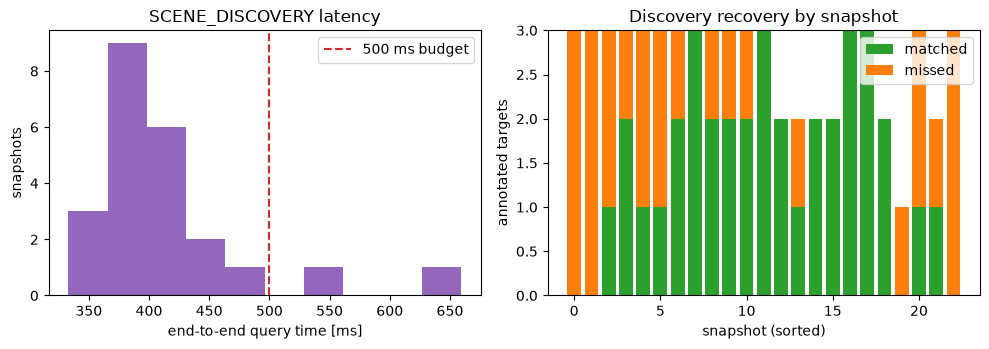

In [3]:
def pct(value):
    return "n/a" if value is None else f"{100.0 * value:.1f}%"


print("SCENE_DISCOVERY (full-cloud inference; ROI used after inference for scoring)")
print({
    "snapshots": DISCOVERY["n_snapshots_scored"],
    "targets": DISCOVERY["total_targets"],
    "predictions_in_scoring_roi": DISCOVERY["total_predictions_scored_roi"],
    "precision": pct(DISCOVERY["precision"]),
    "recall": pct(DISCOVERY["recall"]),
    "timeouts": f'{DISCOVERY["timeout_count"]}/{DISCOVERY["query_invocation_count"]}',
    "end_to_end_p95_ms": round(DISCOVERY["end_to_end_runtime_p95_ms"], 1),
    "end_to_end_max_ms": round(DISCOVERY["end_to_end_runtime_max_ms"], 1),
})
print("timeout/query-failure details:")
for invocation in DISCOVERY["invocations"]:
    if invocation["timeout"] or invocation["failures"]:
        print({
            "snapshot": invocation["snapshot"],
            "timeout": invocation["timeout"],
            "failures": invocation["failures"],
        })

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
times = [item["end_to_end_runtime_ms"] for item in DISCOVERY["invocations"]]
axes[0].hist(times, bins=min(10, len(times)), color="tab:purple")
axes[0].axvline(500.0, color="tab:red", linestyle="--", label="500 ms budget")
axes[0].set(
    xlabel="end-to-end query time [ms]",
    ylabel="snapshots",
    title="SCENE_DISCOVERY latency",
)
axes[0].legend()

rows = DISCOVERY["records"]
axes[1].bar(
    range(len(rows)), [item["matched"] for item in rows], label="matched", color="tab:green"
)
axes[1].bar(
    range(len(rows)),
    [item["missed_targets"] for item in rows],
    bottom=[item["matched"] for item in rows],
    label="missed",
    color="tab:orange",
)
axes[1].set(
    xlabel="snapshot (sorted)", ylabel="annotated targets", title="Discovery recovery by snapshot"
)
axes[1].legend()
plt.tight_layout()
plt.show()

### Full-cloud discovery overlay

This representative successful scene is intentionally shown alongside the
aggregate recall above: a good overlay does not erase the missed targets,
timeouts, or false positives in the remaining snapshots.

{'matched': 3, 'missed_targets': 0, 'false_positives': 0, 'status': 'Completed'}


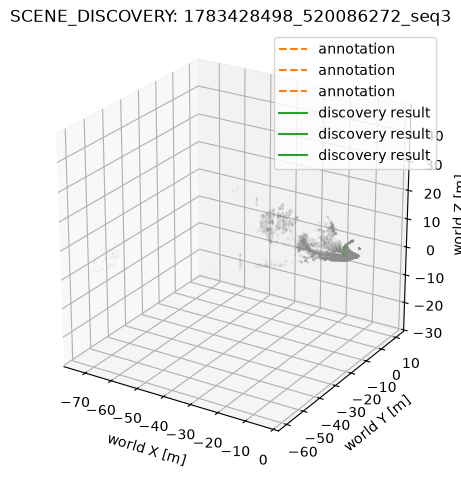

In [4]:
from blockpose.io import apply_transform, load_pcd, load_tf_snapshot


def world_points(snapshot):
    snapshot_dir = REPO_ROOT / "data" / "registration_snapshots" / snapshot
    tf = load_tf_snapshot(snapshot_dir / "tf.yaml")
    return apply_transform(load_pcd(snapshot_dir / "cloud.pcd"), tf.T_world_cloud)


def discovery_overlay(snapshot):
    record = next(item for item in DISCOVERY["records"] if item["snapshot"] == snapshot)
    points = world_points(snapshot)
    shown = points[::max(1, len(points) // 14000)]
    fig = plt.figure(figsize=(8, 5.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(shown[:, 0], shown[:, 1], shown[:, 2], s=0.25, c="0.55", alpha=0.30)
    plotted = [shown]
    for target in record["targets"]:
        draw_pose(ax, target["pose"], "tab:orange", "--", "annotation", plotted)
    for detection in record["detections"]:
        draw_pose(ax, detection["pose"], "tab:green", "-", "discovery result", plotted)
    set_equal_3d(ax, plotted)
    ax.set(
        title=f"SCENE_DISCOVERY: {snapshot}",
        xlabel="world X [m]",
        ylabel="world Y [m]",
        zlabel="world Z [m]",
    )
    ax.view_init(elev=24, azim=-58)
    ax.legend(loc="upper right")
    print({key: record[key] for key in ("matched", "missed_targets", "false_positives", "status")})
    plt.show()


discovery_overlay("1783428498_520086272_seq3")

## `REFINE_BLOCK`: plan-conditioned verification

The current improvement is a verification facade that consumes a plan prior
and reports a status and observability rather than pretending all blocks are
blind-discovery cases.  The fixture prior is leave-one-snapshot-out; it is
useful for development but not independent test data.  Every evaluated target
is present, so the table below deliberately makes **no Missing-status accuracy
claim**.

REFINE_BLOCK (LOSO plan priors; present targets only)
{'planned_targets': 15, 'status_counts': {'Confirmed': 10, 'Deviated': 5}, 'observability': {'PartiallyConstrained': 8, 'WellConstrained': 7}, 'precise_pose_samples': 14, 'translation_p50_mm': 18.34, 'translation_p95_mm': 44.46, 'rotation_p50_deg': 1.379, 'rotation_p95_deg': 3.443, 'end_to_end_p95_ms': 102.9, 'timeouts': '0/10'}


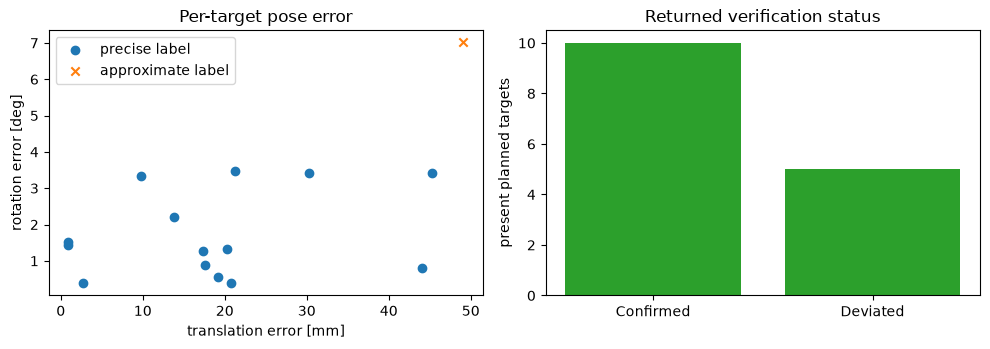

In [5]:
print("REFINE_BLOCK (LOSO plan priors; present targets only)")
print({
    "planned_targets": REFINE["n_planned_targets"],
    "status_counts": REFINE["observed_status_counts_on_present_targets"],
    "observability": {
        key: sum(row["observability"] == key for row in REFINE["records"])
        for key in sorted({row["observability"] for row in REFINE["records"]})
    },
    "precise_pose_samples": REFINE["precise_pose_error_sample_count"],
    "translation_p50_mm": round(1000 * REFINE["translation_error_p50_m"], 2),
    "translation_p95_mm": round(1000 * REFINE["translation_error_p95_m"], 2),
    "rotation_p50_deg": round(REFINE["rotation_error_p50_deg"], 3),
    "rotation_p95_deg": round(REFINE["rotation_error_p95_deg"], 3),
    "end_to_end_p95_ms": round(REFINE["end_to_end_runtime_p95_ms"], 1),
    "timeouts": f'{REFINE["timeout_count"]}/{REFINE["query_invocation_count"]}',
})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
precise = [
    row for row in REFINE["records"]
    if row["annotation"] and row["annotation"]["pose_quality"] == "precise"
]
approximate = [
    row for row in REFINE["records"]
    if row["annotation"] and row["annotation"]["pose_quality"] != "precise"
]
axes[0].scatter([1000 * row["translation_error_m"] for row in precise],
                [row["rotation_error_deg"] for row in precise], color="tab:blue",
                label="precise label")
if approximate:
    axes[0].scatter([1000 * row["translation_error_m"] for row in approximate],
                    [row["rotation_error_deg"] for row in approximate], color="tab:orange",
                    marker="x",
                    label="approximate label")
axes[0].set(
    xlabel="translation error [mm]", ylabel="rotation error [deg]", title="Per-target pose error"
)
axes[0].legend()
statuses = sorted(REFINE["observed_status_counts_on_present_targets"])
axes[1].bar(
    statuses,
    [REFINE["observed_status_counts_on_present_targets"][name] for name in statuses],
    color="tab:green",
)
axes[1].set(ylabel="present planned targets", title="Returned verification status")
plt.tight_layout()
plt.show()

### Honest development-only before/after provenance

The benchmark carries a versioned recorded legacy aggregate alongside the
current candidate and asserts the target keys are identical.  The legacy
aggregate predates a versioned legacy toggle, so it is not replayable with
current code.  The comparison is a **development provenance marker**, not a
causal claim about one algorithmic change and not an acceptance gate.  The
current snapshot topology contains no eligible same-snapshot courses, so no
wall-layout inference improvement is claimed here.

In [6]:
comparison = REFINE["baseline_comparison"]
print({
    "same_target_keys": comparison["same_target_keys"],
    "baseline": comparison["baseline"],
    "candidate": comparison["candidate"],
    "candidate_minus_baseline": comparison["candidate_minus_baseline"],
    "interpretation": "development-only provenance; not a replayed ablation or production claim",
})

{'same_target_keys': True, 'baseline': {'identity': 'verify_placed_v1_baseline', 'git_revision': 'c9f069d', 'evidence_kind': 'recorded_legacy_evidence', 'reproducible_with_current_code': False, 'metrics': {'all_targets': {'target_count': 15, 'mean_translation_m': 0.021807558718617216, 'mean_rotation_deg': 2.451967669575235, 'p95_translation_m': 0.04637385803423495, 'p95_rotation_deg': 4.545344906106746}, 'precise_targets': {'target_count': 14, 'mean_translation_m': 0.019859263524008113, 'mean_rotation_deg': 2.1260415273740243, 'p95_translation_m': 0.04446061915287534, 'p95_rotation_deg': 3.4432942385595}}}, 'candidate': {'identity': 'verify_placed_v1_candidate_v2', 'all_targets': {'target_count': 15, 'pose_error_sample_count': 15, 'mean_translation_m': 0.0208625755521951, 'mean_rotation_deg': 2.094352348548126, 'p95_translation_m': 0.04637385803423495, 'p95_rotation_deg': 4.545344906106746}, 'precise_targets': {'target_count': 14, 'pose_error_sample_count': 14, 'mean_translation_m': 0.

{'status': 'Deviated', 'observability': 'WellConstrained', 'translation_error_m': 0.02031049960601628, 'rotation_error_deg': 1.3265694951356768, 'prior_deviation_m': 0.09071292902487779}


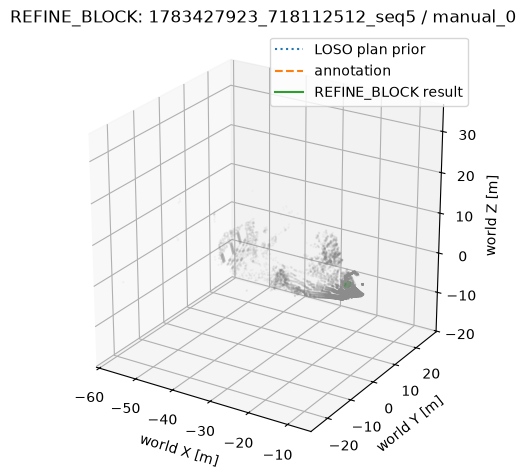

{'status': 'Deviated', 'observability': 'PartiallyConstrained', 'translation_error_m': 0.0027264433960820524, 'rotation_error_deg': 0.37798778316797876, 'prior_deviation_m': 0.01115136597008473}


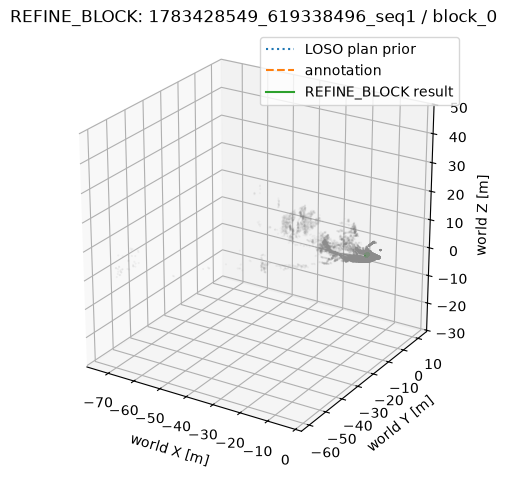

In [7]:
def refine_overlay(snapshot, target_id):
    record = next(
        item for item in REFINE["records"]
        if item["snapshot"] == snapshot and item["target_id"] == target_id
    )
    points = world_points(snapshot)
    shown = points[::max(1, len(points) // 14000)]
    fig = plt.figure(figsize=(8, 5.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(shown[:, 0], shown[:, 1], shown[:, 2], s=0.25, c="0.55", alpha=0.30)
    plotted = [shown]
    draw_pose(ax, record["prior"], "tab:blue", ":", "LOSO plan prior", plotted)
    draw_pose(ax, record["annotation"]["pose"], "tab:orange", "--", "annotation", plotted)
    draw_pose(ax, record["result"], "tab:green", "-", "REFINE_BLOCK result", plotted)
    set_equal_3d(ax, plotted)
    ax.set(
        title=f"REFINE_BLOCK: {snapshot} / {target_id}",
        xlabel="world X [m]",
        ylabel="world Y [m]",
        zlabel="world Z [m]",
    )
    ax.view_init(elev=24, azim=-58)
    ax.legend(loc="upper right")
    print({
        key: record[key]
        for key in (
            "status", "observability", "translation_error_m", "rotation_error_deg",
            "prior_deviation_m",
        )
    })
    plt.show()


refine_overlay("1783427923_718112512_seq5", "manual_0")
refine_overlay("1783428549_619338496_seq1", "block_0")

## `REFINE_GRASPED` is deliberately withheld

The reviewed snapshot taxonomy has gripped targets, but these legacy XYZ
captures lack an independent FK/grasp pose, its covariance, and a gripper
trajectory.  Inferring those inputs from the annotation would turn the prior
into ground truth.  Therefore this mode returns no synthetic-looking pose and
remains unavailable until the recorded ROS fields are supplied.

In [8]:
print({
    "mode": GRIPPED["mode"],
    "status": GRIPPED["status"],
    "reviewed_targets": GRIPPED["n_reviewed_gripped_targets"],
    "reasons": GRIPPED["limitations"],
})
for record in GRIPPED["records"]:
    print({
        "snapshot": record["snapshot"],
        "target_id": record["target_id"],
        "status": record["status"],
        "reason": record["reason"],
    })

{'mode': 'REFINE_GRASPED', 'status': 'unavailable', 'reviewed_targets': 4, 'reasons': ['Do not derive a grasp prior from the annotated target pose.', 'No gripper filtering or FK covariance can be validated from XYZ snapshots.']}
{'snapshot': '1783428997_818953216_seq3', 'target_id': 'manual_0', 'status': 'NotRun', 'reason': 'no independent FK/grasp prior, covariance, or gripper trajectory in snapshot'}
{'snapshot': '1783429057_917983488_seq2', 'target_id': 'manual_2', 'status': 'NotRun', 'reason': 'no independent FK/grasp prior, covariance, or gripper trajectory in snapshot'}
{'snapshot': '1783429344_720968448_seq6', 'target_id': 'block_2', 'status': 'NotRun', 'reason': 'no independent FK/grasp prior, covariance, or gripper trajectory in snapshot'}
{'snapshot': '1783429345_020967424_seq4', 'target_id': 'block_3', 'status': 'NotRun', 'reason': 'no independent FK/grasp prior, covariance, or gripper trajectory in snapshot'}


## Retained synthetic failures

Synthetic scenes remain useful for preserving known geometric limits.  A
seamless touching row has no measured internal interface, and the buried lower
block in a stack has no visible surface.  Blind discovery should not invent
separate measurements for either; planned verification may report a
layout-inferred result only when a real plan and observability rules justify it.

{'ground_truth_blocks': 3, 'detections': 0}


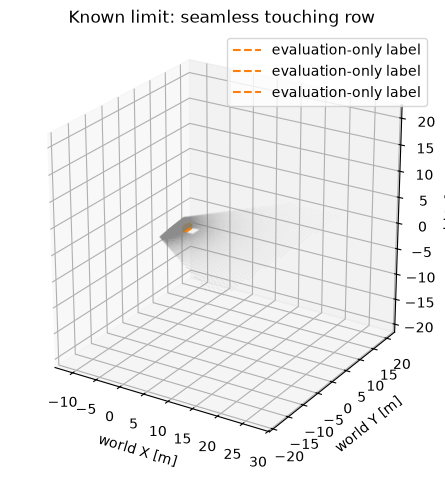

{'ground_truth_blocks': 2, 'detections': 1}


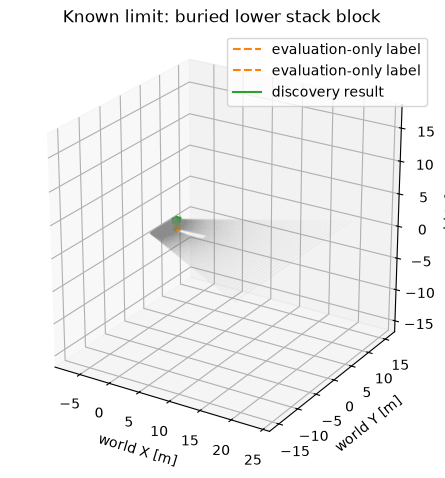

In [9]:
from blockpose.detection import DetectionParams, detect_scene_sample
from blockpose.scenario_matrix import generate_scenario_matrix

SYNTHETIC = {case.name: sample for case, sample in generate_scenario_matrix(0)}


def synthetic_overlay(name, title):
    sample = SYNTHETIC[name]
    detections = detect_scene_sample(sample, DetectionParams())
    shown = sample.points[::max(1, len(sample.points) // 12000)]
    fig = plt.figure(figsize=(8, 5.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(shown[:, 0], shown[:, 1], shown[:, 2], s=0.25, c="0.55", alpha=0.30)
    plotted = [shown]
    def as_record(pose):
        from blockpose.pose import rotmat_to_quat_xyzw
        return {
            "position_m": pose.position,
            "orientation_xyzw": rotmat_to_quat_xyzw(pose.rotation),
            "dimensions_m": pose.dims,
        }
    for pose in sample.ground_truth:
        draw_pose(ax, as_record(pose), "tab:orange", "--", "evaluation-only label", plotted)
    for pose in detections:
        draw_pose(ax, as_record(pose), "tab:green", "-", "discovery result", plotted)
    set_equal_3d(ax, plotted)
    ax.set(title=title, xlabel="world X [m]", ylabel="world Y [m]", zlabel="world Z [m]")
    ax.view_init(elev=24, azim=-58)
    ax.legend(loc="upper right")
    print({"ground_truth_blocks": len(sample.ground_truth), "detections": len(detections)})
    plt.show()


synthetic_overlay("touching_row", "Known limit: seamless touching row")
synthetic_overlay("two_stack", "Known limit: buried lower stack block")

## Reproduce and next evidence needed

For a machine-readable artifact, run:

```bash
mkdir -p out
uv run python tools/eval_detector_modes.py --output out/frozen-mode-benchmark.json
```

The next dataset must preserve per-point time, intensity, beam/scan IDs,
no-return rays, TF trajectory, and gripper/FK state.  That enables deskew and
ray-consistent evidence, a fair `REFINE_GRASPED` benchmark, and a held-out
recording-session split before any production claim or C++ runtime switch.